# 02 · Results

**This notebook trains nothing.** It reads `reports/metrics/*.json` and the figures in `reports/figures/`, the
same files `reports/results.md` is generated from, so every number here matches the README and the documentation.
To regenerate them: `python -m src.train --protocol random`, `python -m src.train --protocol time`,
`python -m src.report`.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.models import LABELS  # noqa: E402

REPORTS = ROOT / "reports"
metrics = {p: json.loads((REPORTS / "metrics" / f"{p}.json").read_text(encoding="utf-8")) for p in ("time", "random")}
PROTOCOL = {"time": "B: time-ordered", "random": "A: stratified"}
pd.set_option("display.width", 160, "display.max_columns", 16, "display.precision", 3)


def figure(name):
    display(Image(filename=str(REPORTS / "figures" / name)))


for p, m in metrics.items():
    s = m["split"]
    print(f"Protocol {PROTOCOL[p]:16s}", "  ".join(f"{b}: {v['rows']:,} rows / {v['frauds']} frauds" for b, v in s.items()))

Protocol B: time-ordered  train: 170,236 rows / 342 frauds  val: 56,746 rows / 57 frauds  test: 56,744 rows / 74 frauds
Protocol A: stratified    train: 226,980 rows / 378 frauds  test: 56,746 rows / 95 frauds


## Ranking quality on the test sets

In [2]:
rows = []
for p, m in metrics.items():
    for k, r in m["models"].items():
        te = r["test"]
        rows.append({
            "protocol": PROTOCOL[p], "model": LABELS[r["model"]], "class weights": "on" if r["weighted"] else "off",
            "PR-AUC": te["pr_auc"], "CI low": te["pr_auc_ci95"][0], "CI high": te["pr_auc_ci95"][1],
            "ROC-AUC": te["roc_auc"], "recall @ 1% FPR": te["recall_at_1pct_fpr"],
            "CV PR-AUC (A)": r["selection"].get("cv_mean"), "CV SD (A)": r["selection"].get("cv_sd"),
        })
ranking = pd.DataFrame(rows)
ranking

,protocol,model,class weights,PR-AUC,CI low,CI high,ROC-AUC,recall @ 1% FPR,CV PR-AUC (A),CV SD (A)
0,B: time-ordered,Logistic regression,on,0.745,0.637,0.859,0.981,0.878,NaN,NaN
1,B: time-ordered,Logistic regression,off,0.699,0.600,0.796,0.971,0.851,NaN,NaN
2,B: time-ordered,Random forest,on,0.812,0.726,0.890,0.965,0.865,NaN,NaN
3,B: time-ordered,Random forest,off,0.794,0.703,0.874,0.950,0.865,NaN,NaN
4,B: time-ordered,XGBoost,on,0.785,0.693,0.868,0.970,0.878,NaN,NaN
5,B: time-ordered,XGBoost,off,0.796,0.707,0.877,0.978,0.851,NaN,NaN
6,A: stratified,Logistic regression,on,0.679,0.584,0.786,0.963,0.853,0.739,0.025
7,A: stratified,Logistic regression,off,0.699,0.608,0.797,0.957,0.832,0.755,0.033
8,A: stratified,Random forest,on,0.812,0.736,0.884,0.961,0.863,0.844,0.037
9,A: stratified,Random forest,off,0.802,0.726,0.873,0.947,0.863,0.841,0.040


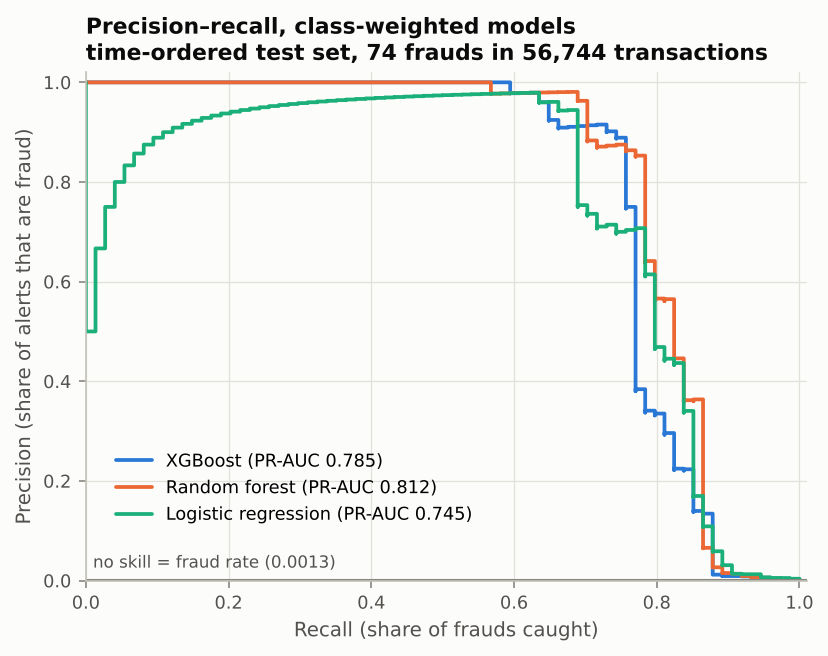

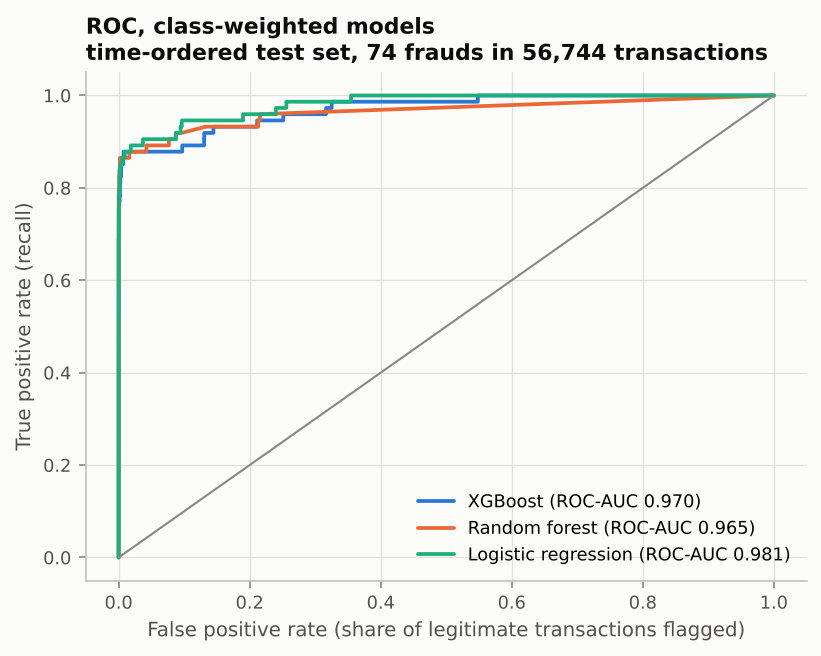

In [3]:
figure("pr_curves_time.png")
figure("roc_curves_time.png")

In [4]:
pd.DataFrame([
    {"comparison": k.replace("_minus_", " − "), "protocol": PROTOCOL[p], "difference": c["diff"],
     "CI low": c["diff_ci95"][0], "CI high": c["diff_ci95"][1], "first model wins": c["share_of_resamples_a_wins"]}
    for p, m in metrics.items() for k, c in m["comparisons"].items()
])

,comparison,protocol,difference,CI low,CI high,first model wins
0,xgb_w − rf_w,B: time-ordered,-0.027,-0.055,-0.006,0.004
1,xgb_w − logreg_w,B: time-ordered,0.040,-0.027,0.111,0.731
2,rf_w − logreg_w,B: time-ordered,0.067,0.003,0.139,0.984
3,xgb_w − rf_w,A: stratified,0.009,-0.004,0.025,0.896
4,xgb_w − logreg_w,A: stratified,0.142,0.066,0.215,1.000
5,rf_w − logreg_w,A: stratified,0.133,0.058,0.203,1.000


## The operating point: threshold chosen on validation, applied once to the test block

In [5]:
r = metrics["time"]["main_cost_ratio"]
print(f"a missed fraud costs r = {r} reviews")
pd.DataFrame([
    {"model": LABELS[res["model"]], "class weights": "on" if res["weighted"] else "off",
     **{k: res["test"]["operating_point"][k] for k in ("threshold", "alerts", "tp", "fp", "fn", "precision", "recall", "cost")}}
    for res in metrics["time"]["models"].values()
]).rename(columns={"tp": "frauds caught", "fp": "false alerts", "fn": "frauds missed"})

a missed fraud costs r = 20 reviews


,model,class weights,threshold,alerts,frauds caught,false alerts,frauds missed,precision,recall,cost
0,Logistic regression,on,1.000,72,53,19,21,0.736,0.716,439.0
1,Logistic regression,off,0.036,165,61,104,13,0.370,0.824,364.0
2,Random forest,on,0.133,105,59,46,15,0.562,0.797,346.0
3,Random forest,off,0.142,80,57,23,17,0.713,0.770,363.0
4,XGBoost,on,0.136,92,57,35,17,0.620,0.770,375.0
5,XGBoost,off,0.053,87,58,29,16,0.667,0.784,349.0


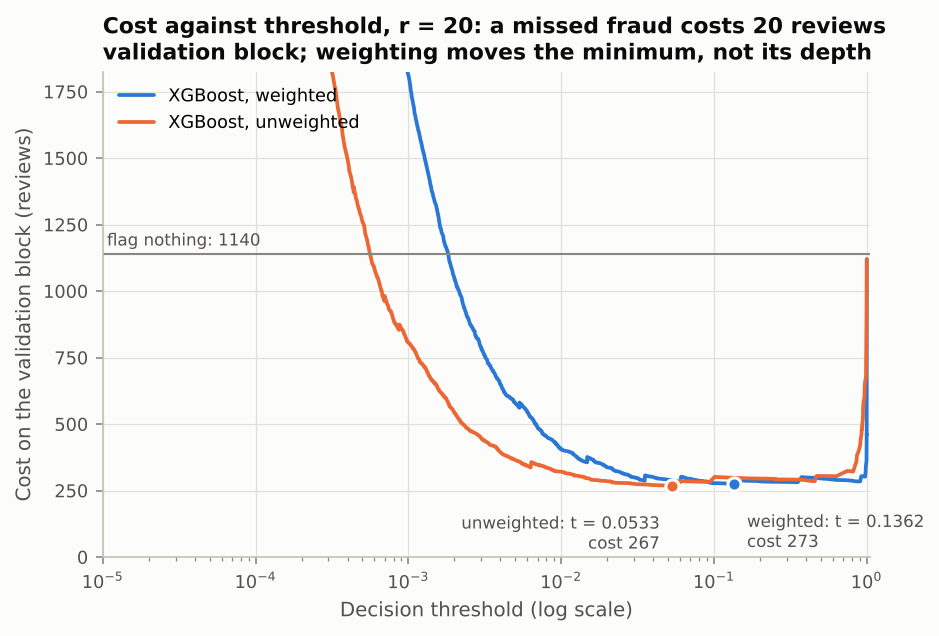

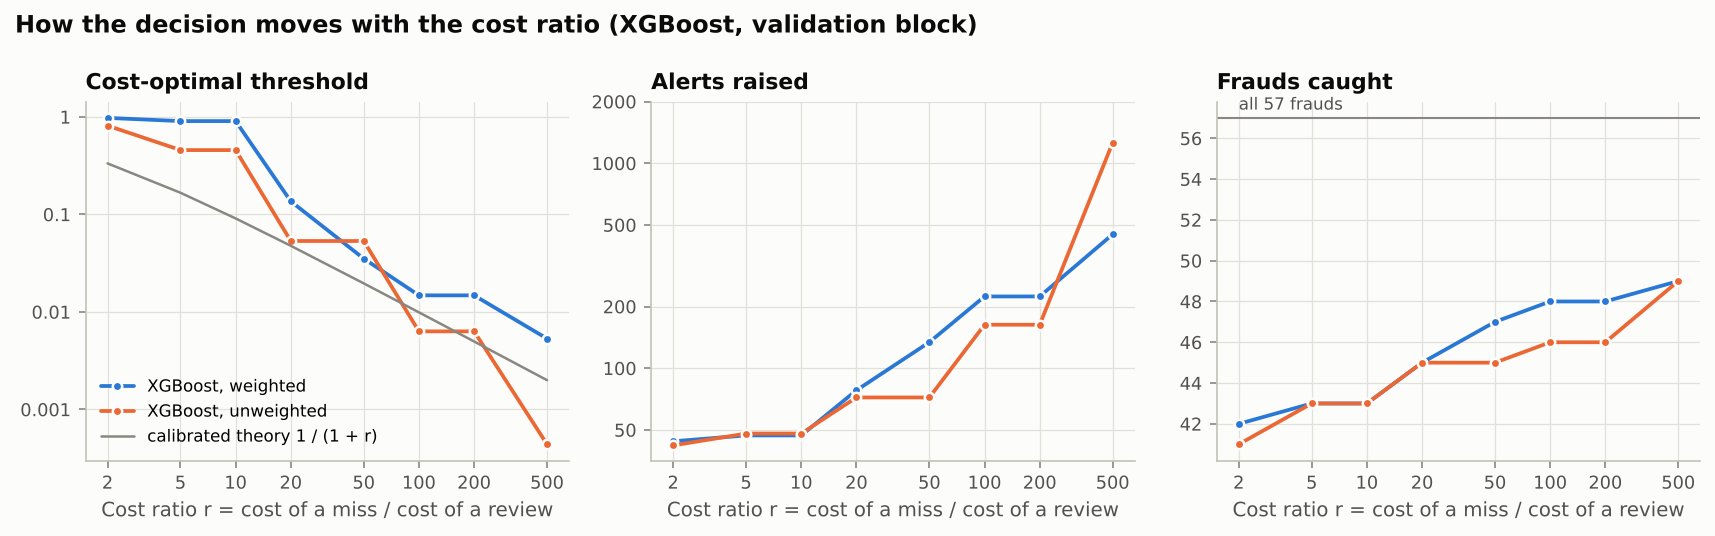

In [6]:
figure("cost_curve_time.png")
figure("threshold_vs_cost_ratio.png")

## E2: class weights vs threshold tuning (selection scores)

In [7]:
pd.DataFrame([
    {"model": LABELS[name], "protocol": PROTOCOL[p], "PR-AUC weighted": e["pr_auc_weighted"],
     "PR-AUC unweighted": e["pr_auc_unweighted"], "difference": e["pr_auc_diff"],
     "CI low": e["pr_auc_diff_ci95"][0], "CI high": e["pr_auc_diff_ci95"][1],
     "threshold weighted": e["threshold_weighted"], "threshold unweighted": e["threshold_unweighted"],
     "odds theory": e["odds_theory_threshold_weighted"], "Spearman rho": e["spearman_rho"]}
    for p, m in metrics.items() for name, e in m["class_weight_experiment"].items()
]).round(4)

,model,protocol,PR-AUC weighted,PR-AUC unweighted,difference,CI low,CI high,threshold weighted,threshold unweighted,odds theory,Spearman rho
0,Logistic regression,B: time-ordered,0.754,0.611,1.435e-01,0.070,0.222,1.000,0.036,0.948,0.838
1,Random forest,B: time-ordered,0.768,0.765,2.600e-03,-0.017,0.024,0.133,0.142,0.988,0.439
2,XGBoost,B: time-ordered,0.789,0.779,9.500e-03,-0.006,0.026,0.136,0.053,0.966,0.863
3,Logistic regression,A: stratified,0.738,0.753,-1.570e-02,-0.034,0.003,0.972,0.018,0.917,0.713
4,Random forest,A: stratified,0.843,0.840,3.400e-03,-0.006,0.013,0.216,0.111,0.987,0.424
5,XGBoost,A: stratified,0.852,0.852,-6.000e-04,-0.006,0.005,0.160,0.062,0.975,0.840


## E3: how much does a random split flatter the models?

In [8]:
e3 = ranking.pivot_table(index=["model", "class weights"], columns="protocol", values="PR-AUC")
e3["change"] = (e3["B: time-ordered"] - e3["A: stratified"]).round(3)
print("no-skill PR-AUC (test fraud rate):",
      {PROTOCOL[p]: round(m["split"]["test"]["fraud_rate"], 4) for p, m in metrics.items()})
e3

no-skill PR-AUC (test fraud rate): {'B: time-ordered': 0.0013, 'A: stratified': 0.0017}


protocol                           A: stratified  B: time-ordered  change
model               class weights                                        
Logistic regression off                    0.699            0.699  -0.000
                    on                     0.679            0.745   0.066
Random forest       off                    0.802            0.794  -0.008
                    on                     0.812            0.812  -0.000
XGBoost             off                    0.830            0.796  -0.035
                    on                     0.821            0.785  -0.037

## E4: are the scores probabilities?

,brier_raw,brier_sigmoid,expected_frauds_raw,expected_frauds_sigmoid,actual_frauds
xgb_w,0.000506,0.000428,87.619957,69.261852,74.0
xgb_u,0.000410,0.000392,67.704590,69.789881,74.0


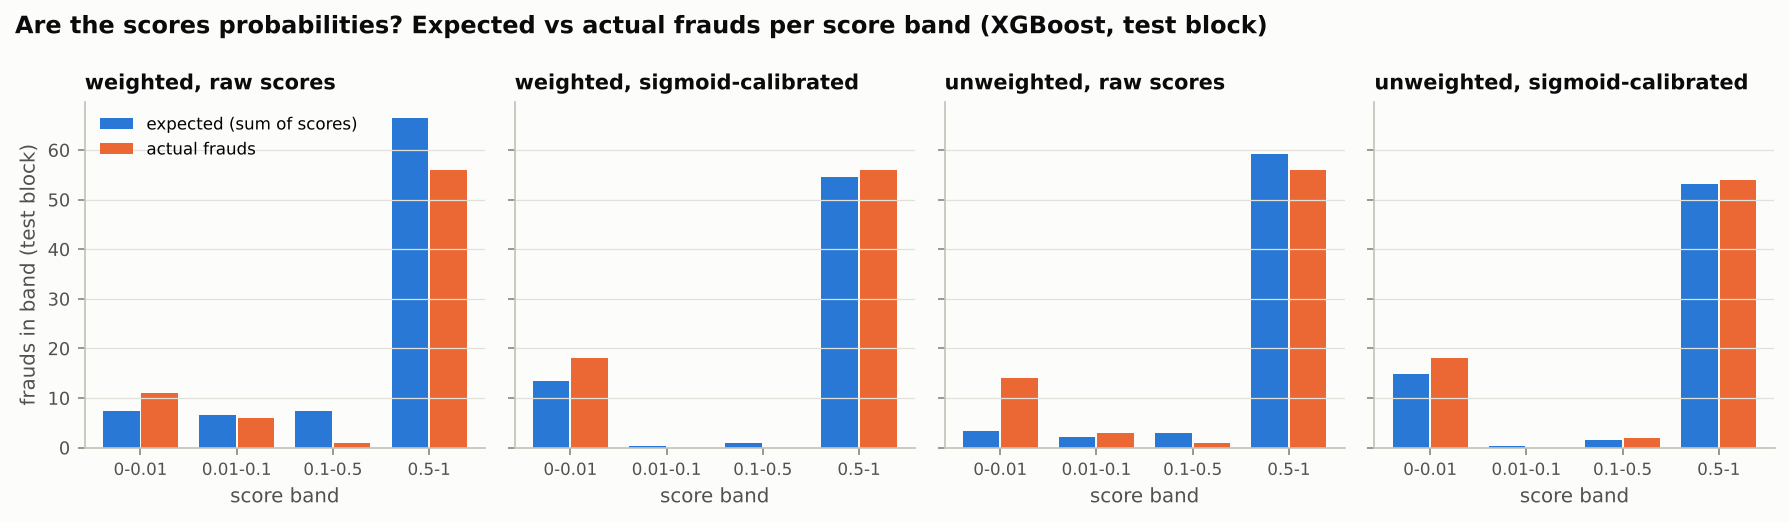

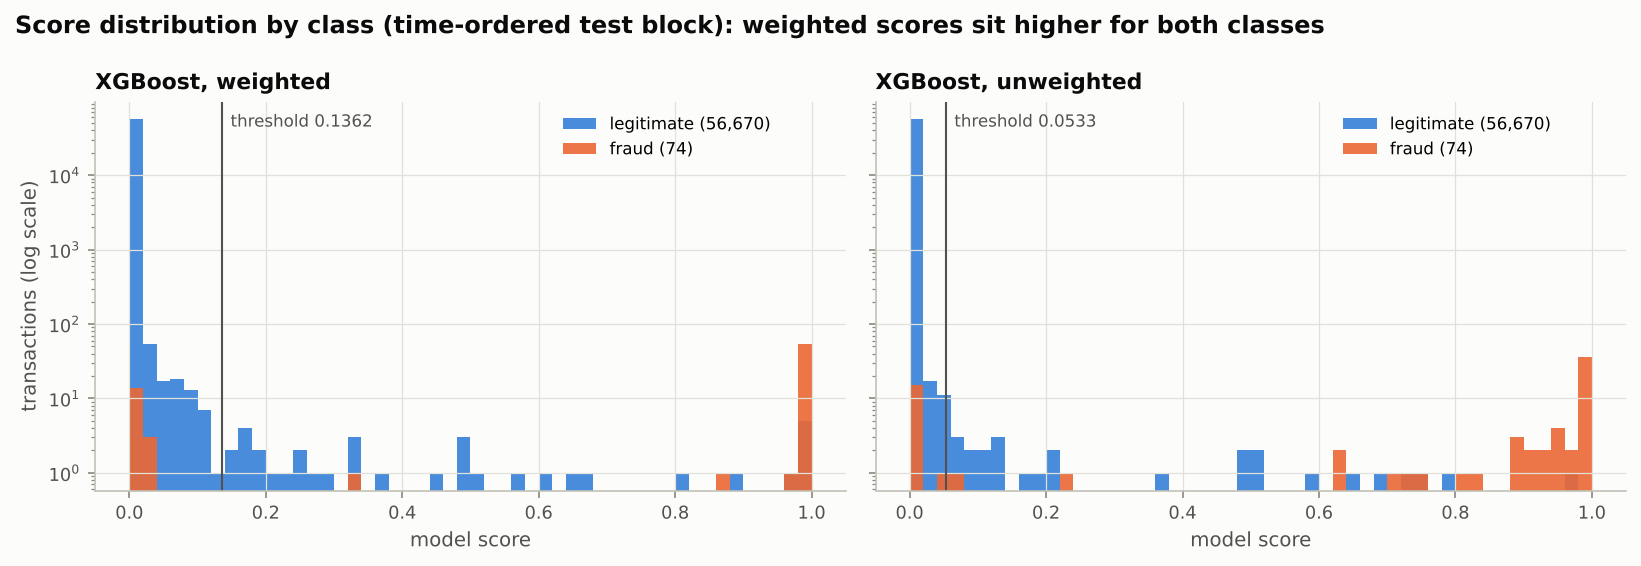

In [9]:
cal = metrics["time"]["calibration"]
columns = ["brier_raw", "brier_sigmoid", "expected_frauds_raw", "expected_frauds_sigmoid", "actual_frauds"]
with pd.option_context("display.precision", 6):
    display(pd.DataFrame(cal).T[columns].astype(float))
figure("score_bands_time.png")
figure("score_hist_time.png")

## E5: what drives the scores, and what the model misses

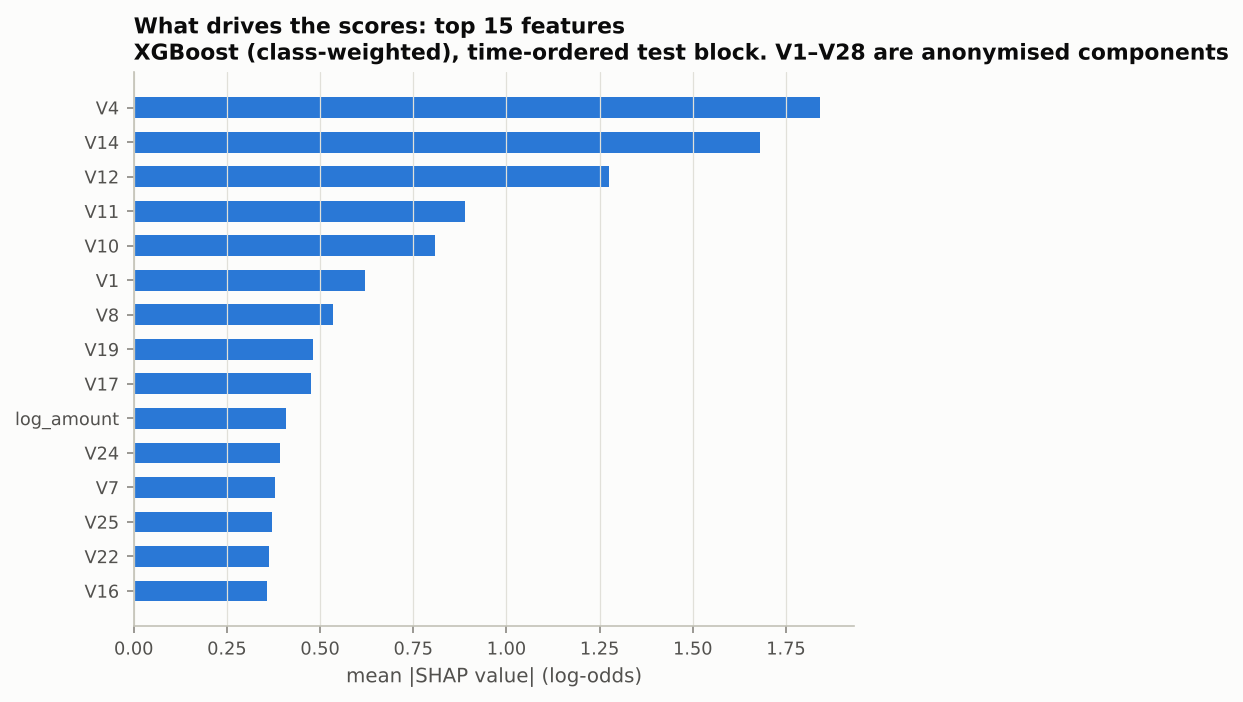

caught: {'n': 57, 'median_amount': 2.0, 'median_score': 0.9998283386230469}
missed: {'n': 17, 'median_amount': 12.31, 'median_score': 0.0002524684532545507}


,amount,hour,score,top_shap
0,1.00,17,3.822e-02,"[[V11, -2.37], [V14, 1.92], [V1, -1.805]]"
1,237.26,17,3.123e-02,"[[V25, -1.664], [V11, -1.509], [V8, -1.505]]"
2,17.39,17,2.829e-02,"[[V14, 1.752], [V4, 1.665], [V1, -1.6]]"
3,12.31,21,1.985e-02,"[[V12, -2.749], [V4, 0.952], [V5, -0.946]]"
4,7.06,19,1.206e-02,"[[V1, -1.655], [V4, 1.402], [V14, 1.275]]"
5,634.30,22,1.153e-02,"[[V14, -2.264], [V10, -1.8], [V17, -0.976]]"
6,3.14,19,5.550e-03,"[[V12, -1.492], [V1, -1.448], [V4, 1.434]]"
7,8.00,16,5.026e-03,"[[V11, -3.015], [V14, 1.367], [V2, -1.168]]"
8,42.53,23,2.525e-04,"[[V12, -2.517], [V4, -1.494], [V1, -1.451]]"
9,19.95,22,1.704e-04,"[[V4, -3.711], [V1, -1.789], [V16, -0.857]]"


In [10]:
ex = metrics["time"]["explanations"]
figure("shap_bar_time.png")
print("caught:", ex["caught_frauds_summary"])
print("missed:", ex["missed_frauds_summary"])
pd.DataFrame(ex["missed_frauds"])

In [11]:
pd.DataFrame(ex["top_false_alerts"])

,amount,hour,score,top_shap
0,0.77,21,0.999,"[[V14, 3.743], [V4, 1.366], [V10, 1.299]]"
1,0.77,22,0.996,"[[V14, 3.517], [V4, 1.453], [V10, 1.167]]"
2,2.00,22,0.995,"[[V14, 2.381], [V10, 1.271], [V4, 1.055]]"
3,0.77,21,0.995,"[[V14, 3.559], [V4, 1.417], [V10, 1.214]]"
4,0.77,16,0.993,"[[V14, 3.424], [V4, 1.449], [V10, 1.291]]"


## E6: when a miss costs its own amount

In [12]:
e6 = metrics["time"]["amount_based_costs"]
print(f"review cost {e6['review_cost']}, handling cost {e6['miss_handling_cost']}; "
      f"money-optimal threshold on validation: {e6['money_threshold_from_validation']:.4f}")
counts = ["alerts", "frauds_caught", "false_alerts", "frauds_missed"]
pd.DataFrame(e6["policies"]).T.astype({c: int for c in counts}).round(2)

review cost 5.0, handling cost 0.0; money-optimal threshold on validation: 0.0352


,total,fraud_lost,review_spend,alerts,frauds_caught,false_alerts,frauds_missed
flag_nothing,7727.67,7727.67,0.0,0,0,0,74
constant_ratio,3096.05,2636.05,460.0,92,57,35,17
money_threshold,3425.05,2635.05,790.0,158,58,100,16
per_transaction,2823.96,2678.96,145.0,29,23,6,51
